In [3]:
from google.api_core import operation
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class AgentState(TypedDict):
    number1: int
    operation: str 
    number2: int 
    final: str 

def adder(state: AgentState) -> AgentState:
    state['final'] = state['number1'] + state['number2']
    return state

def subtractor(state: AgentState) -> AgentState:
    state['final'] = state['number1'] - state['number2']
    return state

def decide_node(state: AgentState) -> AgentState:
    if state['operation'] == "-":
        return "subtraction"
    elif state['operation'] == "+":
        return "addition"

graph = StateGraph(AgentState)

graph.add_node("adder", adder)
graph.add_node("subtractor", subtractor)
graph.add_node("router", lambda state:state)

graph.add_edge(START, "router")
graph.add_conditional_edges(
    "router",
    decide_node,
    {
        "subtraction": "subtractor",
        "addition": "adder"
    }
)
graph.add_edge("adder", END)
graph.add_edge("subtractor", END)

app = graph.compile()

result = app.invoke({"number1": 1, "operation": "-", "number2": 3})
print(result)

{'number1': 1, 'operation': '-', 'number2': 3, 'final': -2}


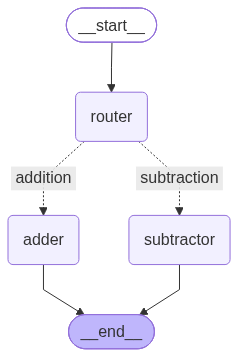

In [4]:
from IPython.display import Image, display 
display(Image(app.get_graph().draw_mermaid_png()))